In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)
# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
for param in model.parameters():
  param.requires_grad = False
# Ganti classifier head untuk 10 kelas
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

In [23]:
# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)(Tambahan saya)
for param in model.parameters():
    param.requires_grad = False
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

trainable_b2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[B2] Trainable Parameters: {trainable_b2:,}")   # -> 5,130

# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
for param in model.layer4.parameters():
    param.requires_grad = True

trainable_b3 = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[B3] Trainable Parameters: {trainable_b3:,}")   # -> 8,398,858


[B2] Trainable Parameters: 5,130
[B3] Trainable Parameters: 8,398,858


In [24]:
# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
for param in model.layer4.parameters():
  param.requires_grad = True
# Optimasi dengan Differential Learning Rate
optimizer = torch.optim.AdamW([
{"params": model.layer4.parameters(),

"lr": 1e-4},

{"params": model.fc.parameters(),

"lr": 1e-3},

], weight_decay=1e-2)
# 4. Pipeline Transformasi Data
# Data latih: menerapkan augmentasi aktif
train_transforms = transforms.Compose([
transforms.Resize(256),
transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
transforms.RandomHorizontalFlip(p=0.5),
transforms.RandomRotation(degrees=15),
transforms.ColorJitter(brightness=0.2, contrast=0.2),
transforms.ToTensor(),
transforms.Normalize(mean=weights.transforms().mean,
std=weights.transforms().std),
])
# Data validasi/uji: hanya deterministik tanpa distorsi
eval_transforms = weights.transforms()
# Verifikasi parameter yang dapat dilatih
trainable_params = sum(p.numel() for p in model.parameters() if
p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")

Trainable Parameters: 8,398,858 / 11,181,642


In [25]:
import os, time, json, random, copy
from pathlib import Path


In [26]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch    :", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device     :", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

PyTorch    : 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device     : cuda (Tesla T4)


In [27]:
#Konfigurasi eksperimen & reproduksibilitas
SEED = 6767
BATCH_SIZE = 32
MAX_EPOCHS = 30        # batas atas; early stopping biasanya berhenti lebih awal
PATIENCE = 5           # early stopping memonitor validation loss
MIN_DELTA = 1e-4       # penurunan minimum val loss agar dianggap membaik
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 2
NUM_CLASSES = 10


DATA_ROOT = Path("/content/data")
OUT_DIR   = Path("/content/outputs")
FIG_DIR   = OUT_DIR / "figures"
CKPT_DIR  = OUT_DIR / "checkpoints"

In [28]:
trainval_ds = OxfordIIITPet(root=DATA_ROOT, split="trainval", target_types="category", download=True)
test_ds     = OxfordIIITPet(root=DATA_ROOT, split="test",     target_types="category", download=True)

print(f"Total kelas: {len(trainval_ds.classes)}")
print(trainval_ds.classes)

Total kelas: 37
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


In [29]:
def set_seed(seed: int = SEED):
    """Kunci seed Python, NumPy, dan PyTorch agar hasil dapat diulang."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    """Seed untuk setiap worker DataLoader (augmentasi acak tetap reproducible)."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED)
print("Seed:", SEED)

Seed: 6767


In [30]:
DATA_ROOT = Path("/content/data")
OUT_DIR   = Path("/content/outputs")
FIG_DIR   = OUT_DIR / "figures"
CKPT_DIR  = OUT_DIR / "checkpoints"
for d in (DATA_ROOT, OUT_DIR, FIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)


In [31]:
#Subset 10 kelas (5 kucing + 5 anjing)
CAT_BREEDS = ["Bengal", "Birman", "Ragdoll", "Russian Blue", "Siamese"]
DOG_BREEDS = ["American Pit Bull Terrier", "Staffordshire Bull Terrier",
              "Beagle", "Basset Hound", "Pomeranian"]
CLASS_NAMES = CAT_BREEDS + DOG_BREEDS

class_to_idx = trainval_ds.class_to_idx
missing = [c for c in CLASS_NAMES if c not in class_to_idx]
assert not missing, f"Nama kelas tidak ditemukan: {missing}"

# Gabungkan split bawaan trainval + test (~200 citra/kelas), lalu split ulang 70/15/15.
# _images & _labels adalah atribut internal torchvision; dipakai agar tidak perlu
# membuka ribuan gambar hanya untuk membaca labelnya.
all_paths  = [str(p) for p in trainval_ds._images] + [str(p) for p in test_ds._images]
all_labels = list(trainval_ds._labels) + list(test_ds._labels)

old_to_new = {class_to_idx[name]: i for i, name in enumerate(CLASS_NAMES)}
df = pd.DataFrame({"path": all_paths, "orig_label": all_labels})
df = df[df["orig_label"].isin(old_to_new)].copy()
df["label"] = df["orig_label"].map(old_to_new)
df["class_name"] = df["label"].map(lambda i: CLASS_NAMES[i])
df["species"] = np.where(df["label"] < len(CAT_BREEDS), "cat", "dog")
df = df.drop(columns="orig_label").reset_index(drop=True)

assert df["path"].is_unique
print(f"Total citra subset: {len(df)}")
display(df["class_name"].value_counts().rename("jumlah").to_frame())

Total citra subset: 1988


,jumlah
class_name,
American Pit Bull Terrier,200
Basset Hound,200
Beagle,200
Bengal,200
Birman,200
Pomeranian,200
Ragdoll,200
Russian Blue,200
Siamese,199


In [32]:
# Sel 5 — Stratified split 70/15/15 + cek kebocoran data
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

# Pastikan tidak ada citra yang muncul di lebih dari satu split
s_tr, s_va, s_te = set(train_df.path), set(val_df.path), set(test_df.path)
assert s_tr.isdisjoint(s_va) and s_tr.isdisjoint(s_te) and s_va.isdisjoint(s_te)
print("Cek data leakage: aman (tidak ada citra yang tumpang tindih antar split)")

# Simpan daftar split sebagai bukti reproduksibilitas
pd.concat([train_df.assign(split="train"),
           val_df.assign(split="val"),
           test_df.assign(split="test")]).to_csv(OUT_DIR / "data_split.csv", index=False)

split_counts = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val":   val_df["class_name"].value_counts(),
    "test":  test_df["class_name"].value_counts(),
}).loc[CLASS_NAMES]
split_counts.loc["TOTAL"] = split_counts.sum()
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
display(split_counts)

Cek data leakage: aman (tidak ada citra yang tumpang tindih antar split)
Train: 1391 | Val: 298 | Test: 299


,train,val,test
class_name,,,
Bengal,140,30,30
Birman,140,30,30
Ragdoll,140,30,30
Russian Blue,140,30,30
Siamese,139,30,30
American Pit Bull Terrier,140,30,30
Staffordshire Bull Terrier,132,28,29
Beagle,140,30,30
Basset Hound,140,30,30


#BAGIAN TRAINING

In [33]:
#Dataset, pipeline transformasi, dan DataLoader
IMAGENET_MEAN = weights.transforms().mean   # [0.485, 0.456, 0.406]
IMAGENET_STD  = weights.transforms().std    # [0.229, 0.224, 0.225]

class PetSubset(Dataset):
    """Dataset sederhana dari DataFrame berisi kolom path & label."""
    def __init__(self, frame, transform=None):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")   # beberapa citra grayscale/RGBA
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

# Data latih DENGAN augmentasi (sesuai starter code)
train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Data latih TANPA augmentasi (untuk B4): hanya Resize/Crop + Normalisasi
train_transforms_noaug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Data validasi/uji: deterministik, tanpa distorsi
eval_transforms = weights.transforms()

def make_loader(frame, transform, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(PetSubset(frame, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                      worker_init_fn=seed_worker, generator=g)

def build_loaders(augment=True):
    return {
        "train":      make_loader(train_df, train_transforms_aug if augment else train_transforms_noaug, shuffle=True),
        "train_eval": make_loader(train_df, eval_transforms, shuffle=False),  # akurasi train "bersih" untuk hitung gap
        "val":        make_loader(val_df,  eval_transforms, shuffle=False),
        "test":       make_loader(test_df, eval_transforms, shuffle=False),
    }

xb, yb = next(iter(build_loaders(augment=True)["train"]))
print("Batch shape:", xb.shape, "| Label contoh:", yb[:8].tolist())


Batch shape: torch.Size([32, 3, 224, 224]) | Label contoh: [9, 7, 2, 0, 9, 8, 5, 6]


In [34]:
#Konstruksi model & verifikasi trainable parameters
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def build_resnet18(mode):
    """mode: 'scratch' (B1) | 'feature_extraction' (B2) | 'finetune_layer4' (B3)"""
    if mode == "scratch":
        model = models.resnet18(weights=None)                     # inisialisasi acak
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        groups = [{"name": "all", "params": list(model.parameters()), "lr": 1e-3}]
        return model, groups

    model = models.resnet18(weights=weights)                      # pretrained ImageNet
    for p in model.parameters():                                  # bekukan seluruh backbone
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)       # head baru (otomatis trainable)

    if mode == "feature_extraction":
        groups = [{"name": "fc", "params": list(model.fc.parameters()), "lr": 1e-3}]
    elif mode == "finetune_layer4":
        for p in model.layer4.parameters():                       # buka blok residual terakhir
            p.requires_grad = True
        groups = [
            {"name": "layer4", "params": list(model.layer4.parameters()), "lr": 1e-4},
            {"name": "fc",     "params": list(model.fc.parameters()),     "lr": 1e-3},
        ]
    else:
        raise ValueError(f"Mode tidak dikenal: {mode}")
    return model, groups

# Verifikasi SEBELUM optimizer dibentuk
for mode in ["scratch", "feature_extraction", "finetune_layer4"]:
    m, _ = build_resnet18(mode)
    tr, tot = count_params(m)
    print(f"{mode:20s} -> Trainable: {tr:>11,} / {tot:,} ({100*tr/tot:.2f}%)")
    if mode == "feature_extraction":
        assert tr == 5_130, "B2 harus hanya melatih fc (512*10 + 10 = 5.130)"
del m


scratch              -> Trainable:  11,181,642 / 11,181,642 (100.00%)
feature_extraction   -> Trainable:       5,130 / 11,181,642 (0.05%)
finetune_layer4      -> Trainable:   8,398,858 / 11,181,642 (75.11%)


In [35]:
#Loop training & evaluasi
def freeze_bn_of_frozen_layers(model):
    """Set eval() pada setiap modul yang seluruh parameternya beku.
    - BatchNorm: running mean/var tidak ikut ter-update.
    - EfficientNet: Stochastic Depth di blok beku dinonaktifkan,
      sehingga backbone beku benar-benar deterministik."""
    for m in model.modules():
        params = list(m.parameters())
        if params and not any(p.requires_grad for p in params):
            m.eval()
# def freeze_bn_of_frozen_layers(model):
#     """BatchNorm tetap meng-update running mean/var saat model.train() walaupun
#     requires_grad=False. Agar backbone benar-benar beku, BN di lapisan beku di-set eval()."""
#     for m in model.modules():
#         if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
#             m.eval()

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    freeze_bn_of_frozen_layers(model)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, n = 0.0, 0
    probs_list, true_list = [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        n += x.size(0)
        probs_list.append(logits.softmax(1).cpu())
        true_list.append(y.cpu())
    probs = torch.cat(probs_list).numpy()
    y_true = torch.cat(true_list).numpy()
    y_pred = probs.argmax(1)
    return {"loss": total_loss / n,
            "acc": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
            "y_true": y_true, "y_pred": y_pred, "probs": probs}


In [36]:
#Runner eksperimen, early stopping, dan penyimpanan log mentah
RESULTS, HISTORIES, PREDICTIONS, MODELS = {}, {}, {}, {}

CONFIG = {
    "seed": SEED, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "min_delta": MIN_DELTA, "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY,
    "loss": "CrossEntropyLoss", "input_size": 224, "normalize_mean": IMAGENET_MEAN,
    "normalize_std": IMAGENET_STD, "classes": CLASS_NAMES,
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "torch": torch.__version__, "torchvision": torchvision.__version__,
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
}

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def save_logs():
    """Tulis ulang semua log setiap kali satu eksperimen selesai."""
    pd.DataFrame(RESULTS.values()).to_csv(OUT_DIR / "summary_metrics.csv", index=False)
    pd.DataFrame([r for h in HISTORIES.values() for r in h]).to_csv(OUT_DIR / "epoch_logs.csv", index=False)
    pred_rows = []
    for exp_id, res in PREDICTIONS.items():
        for path, t, p, pr in zip(test_df["path"], res["y_true"], res["y_pred"], res["probs"]):
            pred_rows.append({"experiment": exp_id, "path": path,
                              "true_label": CLASS_NAMES[t], "pred_label": CLASS_NAMES[p],
                              "confidence": float(pr[p]), "correct": bool(t == p)})
    pd.DataFrame(pred_rows).to_csv(OUT_DIR / "test_predictions.csv", index=False)
    with open(OUT_DIR / "metrics_log.json", "w") as f:
        json.dump({"config": CONFIG, "summary": list(RESULTS.values()),
                   "epoch_logs": HISTORIES}, f, indent=2, default=str)

def run_experiment(exp_id, description, build_fn, augment=True, arch="resnet18", strategy=""):
    set_seed(SEED)
    model, groups = build_fn()
    model = model.to(DEVICE)
    loaders = build_loaders(augment)

    trainable, total = count_params(model)
    in_groups = sum(p.numel() for g in groups for p in g["params"])
    assert trainable == in_groups, "Parameter trainable tidak sama dengan parameter di optimizer!"
    lr_info = {g["name"]: g["lr"] for g in groups}
    lr_str = "; ".join(f"{k}={v:g}" for k, v in lr_info.items())
    print(f"\n=== {exp_id}: {description} ===")
    print(f"Trainable: {trainable:,} / {total:,} | LR: {lr_str} | Augmentasi: {augment}")

    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    history, best_state = [], None
    best_val_loss, best_epoch, wait = float("inf"), 0, 0
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    sync(); t_start = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        t_ep = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, loaders["train"], criterion, optimizer)
        val = evaluate(model, loaders["val"], criterion)
        sync(); ep_time = time.perf_counter() - t_ep

        history.append({"experiment": exp_id, "epoch": epoch,
                        "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": val["loss"], "val_acc": val["acc"], "val_macro_f1": val["macro_f1"],
                        "lr_groups": "; ".join(f"{g['name']}={g['lr']:g}" for g in optimizer.param_groups),
                        "epoch_time_s": ep_time})

        if val["loss"] < best_val_loss - MIN_DELTA:
            best_val_loss, best_epoch, wait = val["loss"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            flag = " *best"
        else:
            wait += 1
            flag = ""
        print(f"[{exp_id}] ep {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {val['loss']:.4f} acc {val['acc']:.3f} | {ep_time:.1f}s{flag}")
        if wait >= PATIENCE:
            print(f"Early stopping di epoch {epoch} (best epoch = {best_epoch})")
            break

    sync(); train_time = time.perf_counter() - t_start
    peak_mem = torch.cuda.max_memory_allocated() / 1024**2 if DEVICE.type == "cuda" else None

    # Kembalikan bobot terbaik (val loss terendah), lalu evaluasi final
    model.load_state_dict(best_state)
    torch.save(best_state, CKPT_DIR / f"{exp_id}.pt")
    val_res = evaluate(model, loaders["val"], criterion)
    train_clean = evaluate(model, loaders["train_eval"], criterion)
    sync(); t0 = time.perf_counter()
    test_res = evaluate(model, loaders["test"], criterion)
    sync(); infer_time = time.perf_counter() - t0

    RESULTS[exp_id] = {
        "experiment": exp_id, "description": description, "arch": arch, "strategy": strategy,
        "augmentation": augment, "trainable_params": trainable, "total_params": total,
        "trainable_pct": round(100 * trainable / total, 2), "lr_groups": lr_str,
        "best_epoch": best_epoch, "epochs_run": len(history), "early_stopped": wait >= PATIENCE,
        "train_time_s": round(train_time, 1), "sec_per_epoch": round(train_time / len(history), 1),
        "peak_gpu_mem_mb": round(peak_mem, 1) if peak_mem else None,
        "best_val_loss": round(val_res["loss"], 4), "val_acc": round(val_res["acc"], 4),
        "val_macro_f1": round(val_res["macro_f1"], 4),
        "train_acc_clean": round(train_clean["acc"], 4),
        "gap_train_val": round(train_clean["acc"] - val_res["acc"], 4),
        "test_loss": round(test_res["loss"], 4), "test_acc": round(test_res["acc"], 4),
        "test_macro_f1": round(test_res["macro_f1"], 4),
        "infer_ms_per_img": round(1000 * infer_time / len(test_df), 2), "seed": SEED,
    }
    HISTORIES[exp_id], PREDICTIONS[exp_id], MODELS[exp_id] = history, test_res, model
    save_logs()
    print(f">> {exp_id} selesai | val acc {val_res['acc']:.4f} | test macro F1 {test_res['macro_f1']:.4f} "
          f"| waktu {train_time:.0f}s | log tersimpan di {OUT_DIR}")
    return RESULTS[exp_id]


In [37]:
#B1: ResNet-18 dari inisialisasi acak
run_experiment("B1", "Baseline from scratch (weights=None)",
               lambda: build_resnet18("scratch"), augment=True, strategy="from_scratch")



=== B1: Baseline from scratch (weights=None) ===
Trainable: 11,181,642 / 11,181,642 | LR: all=0.001 | Augmentasi: True
[B1] ep 01 | train loss 2.2591 acc 0.198 | val loss 2.2486 acc 0.225 | 14.7s *best
[B1] ep 02 | train loss 1.9907 acc 0.274 | val loss 2.2126 acc 0.208 | 16.8s *best
[B1] ep 03 | train loss 1.9385 acc 0.298 | val loss 1.9252 acc 0.319 | 14.6s *best
[B1] ep 04 | train loss 1.8505 acc 0.321 | val loss 1.8870 acc 0.349 | 14.5s *best
[B1] ep 05 | train loss 1.7774 acc 0.351 | val loss 1.7576 acc 0.376 | 14.5s *best
[B1] ep 06 | train loss 1.6920 acc 0.383 | val loss 1.6522 acc 0.436 | 15.6s *best
[B1] ep 07 | train loss 1.6300 acc 0.392 | val loss 1.8059 acc 0.369 | 15.0s
[B1] ep 08 | train loss 1.6107 acc 0.405 | val loss 1.7085 acc 0.393 | 14.4s
[B1] ep 09 | train loss 1.5738 acc 0.425 | val loss 1.5897 acc 0.433 | 14.7s *best
[B1] ep 10 | train loss 1.5000 acc 0.463 | val loss 2.2245 acc 0.305 | 14.6s
[B1] ep 11 | train loss 1.4877 acc 0.452 | val loss 1.3818 acc 0.466

{'experiment': 'B1',
 'description': 'Baseline from scratch (weights=None)',
 'arch': 'resnet18',
 'strategy': 'from_scratch',
 'augmentation': True,
 'trainable_params': 11181642,
 'total_params': 11181642,
 'trainable_pct': 100.0,
 'lr_groups': 'all=0.001',
 'best_epoch': 11,
 'epochs_run': 16,
 'early_stopped': True,
 'train_time_s': 238.5,
 'sec_per_epoch': 14.9,
 'peak_gpu_mem_mb': 898.3,
 'best_val_loss': 1.3818,
 'val_acc': 0.4664,
 'val_macro_f1': 0.4751,
 'train_acc_clean': 0.4889,
 'gap_train_val': 0.0224,
 'test_loss': 1.4077,
 'test_acc': 0.4749,
 'test_macro_f1': 0.4755,
 'infer_ms_per_img': 6.08,
 'seed': 6767}

In [38]:
#B2: backbone beku, hanya fc yang dilatih
run_experiment("B2", "Feature extraction (backbone beku, latih fc)",
               lambda: build_resnet18("feature_extraction"), augment=True, strategy="feature_extraction")



=== B2: Feature extraction (backbone beku, latih fc) ===
Trainable: 5,130 / 11,181,642 | LR: fc=0.001 | Augmentasi: True
[B2] ep 01 | train loss 1.4010 acc 0.568 | val loss 0.7022 acc 0.842 | 13.7s *best
[B2] ep 02 | train loss 0.6051 acc 0.853 | val loss 0.4792 acc 0.846 | 13.7s *best
[B2] ep 03 | train loss 0.4530 acc 0.868 | val loss 0.4371 acc 0.836 | 13.8s *best
[B2] ep 04 | train loss 0.3754 acc 0.883 | val loss 0.3564 acc 0.899 | 13.7s *best
[B2] ep 05 | train loss 0.3272 acc 0.908 | val loss 0.3363 acc 0.896 | 13.9s *best
[B2] ep 06 | train loss 0.3029 acc 0.914 | val loss 0.3532 acc 0.866 | 13.4s
[B2] ep 07 | train loss 0.2967 acc 0.902 | val loss 0.3459 acc 0.859 | 13.8s
[B2] ep 08 | train loss 0.2687 acc 0.921 | val loss 0.3113 acc 0.883 | 14.0s *best
[B2] ep 09 | train loss 0.2525 acc 0.920 | val loss 0.3042 acc 0.886 | 14.1s *best
[B2] ep 10 | train loss 0.2464 acc 0.920 | val loss 0.2986 acc 0.883 | 13.8s *best
[B2] ep 11 | train loss 0.2452 acc 0.922 | val loss 0.2964 a

{'experiment': 'B2',
 'description': 'Feature extraction (backbone beku, latih fc)',
 'arch': 'resnet18',
 'strategy': 'feature_extraction',
 'augmentation': True,
 'trainable_params': 5130,
 'total_params': 11181642,
 'trainable_pct': 0.05,
 'lr_groups': 'fc=0.001',
 'best_epoch': 12,
 'epochs_run': 17,
 'early_stopped': True,
 'train_time_s': 233.8,
 'sec_per_epoch': 13.8,
 'peak_gpu_mem_mb': 375.4,
 'best_val_loss': 0.2814,
 'val_acc': 0.8926,
 'val_macro_f1': 0.8922,
 'train_acc_clean': 0.9382,
 'gap_train_val': 0.0456,
 'test_loss': 0.2312,
 'test_acc': 0.903,
 'test_macro_f1': 0.9026,
 'infer_ms_per_img': 8.93,
 'seed': 6767}

In [39]:
# B3: unfreeze layer4 + fc dengan differential learning rate
run_experiment("B3", "Progressive fine-tuning (layer4 lr=1e-4, fc lr=1e-3)",
               lambda: build_resnet18("finetune_layer4"), augment=True, strategy="finetune_layer4")



=== B3: Progressive fine-tuning (layer4 lr=1e-4, fc lr=1e-3) ===
Trainable: 8,398,858 / 11,181,642 | LR: layer4=0.0001; fc=0.001 | Augmentasi: True
[B3] ep 01 | train loss 0.8892 acc 0.708 | val loss 0.2945 acc 0.899 | 13.7s *best
[B3] ep 02 | train loss 0.2816 acc 0.904 | val loss 0.2803 acc 0.889 | 13.6s *best
[B3] ep 03 | train loss 0.1776 acc 0.946 | val loss 0.2808 acc 0.869 | 13.6s
[B3] ep 04 | train loss 0.1115 acc 0.971 | val loss 0.2487 acc 0.909 | 13.8s *best
[B3] ep 05 | train loss 0.0725 acc 0.983 | val loss 0.3067 acc 0.889 | 14.0s
[B3] ep 06 | train loss 0.0574 acc 0.986 | val loss 0.2992 acc 0.896 | 13.9s
[B3] ep 07 | train loss 0.0398 acc 0.992 | val loss 0.3472 acc 0.879 | 13.9s
[B3] ep 08 | train loss 0.0350 acc 0.994 | val loss 0.3603 acc 0.899 | 13.7s
[B3] ep 09 | train loss 0.0440 acc 0.988 | val loss 0.3026 acc 0.903 | 13.8s
Early stopping di epoch 9 (best epoch = 4)
>> B3 selesai | val acc 0.9094 | test macro F1 0.9295 | waktu 124s | log tersimpan di /content/ou

{'experiment': 'B3',
 'description': 'Progressive fine-tuning (layer4 lr=1e-4, fc lr=1e-3)',
 'arch': 'resnet18',
 'strategy': 'finetune_layer4',
 'augmentation': True,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'trainable_pct': 75.11,
 'lr_groups': 'layer4=0.0001; fc=0.001',
 'best_epoch': 4,
 'epochs_run': 9,
 'early_stopped': True,
 'train_time_s': 124.1,
 'sec_per_epoch': 13.8,
 'peak_gpu_mem_mb': 515.3,
 'best_val_loss': 0.2487,
 'val_acc': 0.9094,
 'val_macro_f1': 0.9089,
 'train_acc_clean': 0.9885,
 'gap_train_val': 0.0791,
 'test_loss': 0.2016,
 'test_acc': 0.9298,
 'test_macro_f1': 0.9295,
 'infer_ms_per_img': 5.98,
 'seed': 6767}

In [40]:
# B4: konfigurasi B3 TANPA augmentasi.
# Skenario "dengan augmentasi" = run B3 (konfigurasi & seed identik), sehingga
# perbandingan B3 vs B4_noaug hanya berbeda pada augmentasi.
run_experiment("B4_noaug", "B3 tanpa augmentasi (hanya Resize/Crop + Normalisasi)",
               lambda: build_resnet18("finetune_layer4"), augment=False, strategy="finetune_layer4")



=== B4_noaug: B3 tanpa augmentasi (hanya Resize/Crop + Normalisasi) ===
Trainable: 8,398,858 / 11,181,642 | LR: layer4=0.0001; fc=0.001 | Augmentasi: False
[B4_noaug] ep 01 | train loss 0.7995 acc 0.730 | val loss 0.2689 acc 0.919 | 9.1s *best
[B4_noaug] ep 02 | train loss 0.1459 acc 0.964 | val loss 0.2443 acc 0.913 | 9.1s *best
[B4_noaug] ep 03 | train loss 0.0471 acc 0.996 | val loss 0.2299 acc 0.909 | 9.7s *best
[B4_noaug] ep 04 | train loss 0.0172 acc 1.000 | val loss 0.2168 acc 0.926 | 9.6s *best
[B4_noaug] ep 05 | train loss 0.0104 acc 1.000 | val loss 0.2216 acc 0.930 | 8.6s
[B4_noaug] ep 06 | train loss 0.0074 acc 1.000 | val loss 0.2214 acc 0.930 | 9.8s
[B4_noaug] ep 07 | train loss 0.0052 acc 1.000 | val loss 0.2328 acc 0.913 | 9.6s
[B4_noaug] ep 08 | train loss 0.0044 acc 1.000 | val loss 0.2393 acc 0.926 | 8.4s
[B4_noaug] ep 09 | train loss 0.0039 acc 1.000 | val loss 0.2422 acc 0.913 | 9.7s
Early stopping di epoch 9 (best epoch = 4)
>> B4_noaug selesai | val acc 0.9262 |

{'experiment': 'B4_noaug',
 'description': 'B3 tanpa augmentasi (hanya Resize/Crop + Normalisasi)',
 'arch': 'resnet18',
 'strategy': 'finetune_layer4',
 'augmentation': False,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'trainable_pct': 75.11,
 'lr_groups': 'layer4=0.0001; fc=0.001',
 'best_epoch': 4,
 'epochs_run': 9,
 'early_stopped': True,
 'train_time_s': 83.8,
 'sec_per_epoch': 9.3,
 'peak_gpu_mem_mb': 590.7,
 'best_val_loss': 0.2168,
 'val_acc': 0.9262,
 'val_macro_f1': 0.9254,
 'train_acc_clean': 1.0,
 'gap_train_val': 0.0738,
 'test_loss': 0.191,
 'test_acc': 0.9298,
 'test_macro_f1': 0.9286,
 'infer_ms_per_img': 5.76,
 'seed': 6767}

In [41]:
cols = ["experiment", "strategy", "augmentation", "trainable_params", "lr_groups", "best_epoch",
        "epochs_run", "train_time_s", "val_acc", "test_macro_f1", "train_acc_clean", "gap_train_val"]
display(pd.DataFrame(RESULTS.values())[cols])

,experiment,strategy,augmentation,trainable_params,lr_groups,best_epoch,epochs_run,train_time_s,val_acc,test_macro_f1,train_acc_clean,gap_train_val
0,B1,from_scratch,True,11181642,all=0.001,11,16,238.5,0.4664,0.4755,0.4889,0.0224
1,B2,feature_extraction,True,5130,fc=0.001,12,17,233.8,0.8926,0.9026,0.9382,0.0456
2,B3,finetune_layer4,True,8398858,layer4=0.0001; fc=0.001,4,9,124.1,0.9094,0.9295,0.9885,0.0791
3,B4_noaug,finetune_layer4,False,8398858,layer4=0.0001; fc=0.001,4,9,83.8,0.9262,0.9286,1.0000,0.0738


In [42]:
cols = ["experiment", "strategy", "augmentation", "trainable_params", "lr_groups", "best_epoch",
        "epochs_run", "train_time_s", "sec_per_epoch", "peak_gpu_mem_mb",
        "val_acc", "test_macro_f1", "train_acc_clean", "gap_train_val"]
display(pd.DataFrame(RESULTS.values())[cols])


,experiment,strategy,augmentation,trainable_params,lr_groups,best_epoch,epochs_run,train_time_s,sec_per_epoch,peak_gpu_mem_mb,val_acc,test_macro_f1,train_acc_clean,gap_train_val
0,B1,from_scratch,True,11181642,all=0.001,11,16,238.5,14.9,898.3,0.4664,0.4755,0.4889,0.0224
1,B2,feature_extraction,True,5130,fc=0.001,12,17,233.8,13.8,375.4,0.8926,0.9026,0.9382,0.0456
2,B3,finetune_layer4,True,8398858,layer4=0.0001; fc=0.001,4,9,124.1,13.8,515.3,0.9094,0.9295,0.9885,0.0791
3,B4_noaug,finetune_layer4,False,8398858,layer4=0.0001; fc=0.001,4,9,83.8,9.3,590.7,0.9262,0.9286,1.0000,0.0738


#B5 (Bonus)

In [45]:
# B5: model efisien (EfficientNet-B0 & MobileNetV3-Small)
ARCH_WEIGHTS = {
    "resnet18":           models.ResNet18_Weights.IMAGENET1K_V1,
    "efficientnet_b0":    models.EfficientNet_B0_Weights.IMAGENET1K_V1,
    "mobilenet_v3_small": models.MobileNet_V3_Small_Weights.IMAGENET1K_V1,
}

def build_efficient_model(arch, mode):
    """arch: 'efficientnet_b0' | 'mobilenet_v3_small'
    mode: 'feature_extraction' (setara B2) | 'finetune' (setara B3)
    'tail' = stage terakhir beresolusi 7x7, padanan layer4 pada ResNet-18."""
    if arch == "efficientnet_b0":
        model = models.efficientnet_b0(weights=ARCH_WEIGHTS[arch])
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
        head, head_name = model.classifier[1], "classifier[1]"
        tail, tail_name = model.features[6:], "features[6:]"
    elif arch == "mobilenet_v3_small":
        model = models.mobilenet_v3_small(weights=ARCH_WEIGHTS[arch])
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, NUM_CLASSES)
        head, head_name = model.classifier[3], "classifier[3]"
        tail = nn.ModuleList([model.features[9:], model.classifier[0]])
        tail_name = "features[9:]+classifier[0]"
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    if mode == "feature_extraction":
        groups = [{"name": head_name, "params": list(head.parameters()), "lr": 1e-3}]
    elif mode == "finetune":
        for p in tail.parameters():
            p.requires_grad = True
        groups = [
            {"name": tail_name, "params": list(tail.parameters()), "lr": 1e-4},
            {"name": head_name, "params": list(head.parameters()), "lr": 1e-3},
        ]
    else:
        raise ValueError(f"Mode tidak dikenal: {mode}")
    return model, groups

# Verifikasi parameter sebelum training
for arch in ["efficientnet_b0", "mobilenet_v3_small"]:
    for mode in ["feature_extraction", "finetune"]:
        m, _ = build_efficient_model(arch, mode)
        tr, tot = count_params(m)
        print(f"{arch:20s} {mode:18s} -> Trainable: {tr:>10,} / {tot:,} ({100*tr/tot:.2f}%)")
del m


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


efficientnet_b0      feature_extraction -> Trainable:     12,810 / 4,020,358 (0.32%)
efficientnet_b0      finetune           -> Trainable:  3,168,550 / 4,020,358 (78.81%)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 51.9MB/s]


mobilenet_v3_small   feature_extraction -> Trainable:     10,250 / 1,528,106 (0.67%)
mobilenet_v3_small   finetune           -> Trainable:  1,337,586 / 1,528,106 (87.53%)


In [46]:
#Konfigurasi terbaik dipilih dari VALIDATION (bukan test) agar tidak ada leakage
candidates = [e for e in ["B2", "B3", "B4_noaug"] if e in RESULTS]
BEST_EXP = max(candidates, key=lambda e: (RESULTS[e]["val_acc"], -RESULTS[e]["best_val_loss"]))
BEST_MODE = "feature_extraction" if RESULTS[BEST_EXP]["strategy"] == "feature_extraction" else "finetune"
BEST_AUG = bool(RESULTS[BEST_EXP]["augmentation"])

display(pd.DataFrame([RESULTS[e] for e in candidates])[["experiment", "strategy", "augmentation", "val_acc", "best_val_loss"]])
print(f"Konfigurasi terbaik: {BEST_EXP} -> mode={BEST_MODE}, augmentasi={BEST_AUG}")

,experiment,strategy,augmentation,val_acc,best_val_loss
0,B2,feature_extraction,True,0.8926,0.2814
1,B3,finetune_layer4,True,0.9094,0.2487
2,B4_noaug,finetune_layer4,False,0.9262,0.2168


Konfigurasi terbaik: B4_noaug -> mode=finetune, augmentasi=False


In [47]:
# B5a: EfficientNet-B0 dengan konfigurasi terbaik

run_experiment("B5_effnet_b0", f"EfficientNet-B0 ({BEST_MODE}, aug={BEST_AUG}, mengikuti {BEST_EXP})",
               lambda: build_efficient_model("efficientnet_b0", BEST_MODE),
               augment=BEST_AUG, arch="efficientnet_b0", strategy=BEST_MODE)


=== B5_effnet_b0: EfficientNet-B0 (finetune, aug=False, mengikuti B4_noaug) ===
Trainable: 3,168,550 / 4,020,358 | LR: features[6:]=0.0001; classifier[1]=0.001 | Augmentasi: False
[B5_effnet_b0] ep 01 | train loss 1.1102 acc 0.721 | val loss 0.3381 acc 0.889 | 10.2s *best
[B5_effnet_b0] ep 02 | train loss 0.2883 acc 0.915 | val loss 0.2391 acc 0.916 | 9.9s *best
[B5_effnet_b0] ep 03 | train loss 0.1455 acc 0.968 | val loss 0.2192 acc 0.916 | 8.6s *best
[B5_effnet_b0] ep 04 | train loss 0.0773 acc 0.978 | val loss 0.1895 acc 0.930 | 9.8s *best
[B5_effnet_b0] ep 05 | train loss 0.0538 acc 0.995 | val loss 0.2101 acc 0.923 | 9.9s
[B5_effnet_b0] ep 06 | train loss 0.0372 acc 0.996 | val loss 0.2116 acc 0.930 | 9.8s
[B5_effnet_b0] ep 07 | train loss 0.0250 acc 0.998 | val loss 0.2284 acc 0.923 | 8.5s
[B5_effnet_b0] ep 08 | train loss 0.0252 acc 0.996 | val loss 0.2104 acc 0.926 | 9.9s
[B5_effnet_b0] ep 09 | train loss 0.0223 acc 0.996 | val loss 0.2432 acc 0.930 | 9.8s
Early stopping di ep

{'experiment': 'B5_effnet_b0',
 'description': 'EfficientNet-B0 (finetune, aug=False, mengikuti B4_noaug)',
 'arch': 'efficientnet_b0',
 'strategy': 'finetune',
 'augmentation': False,
 'trainable_params': 3168550,
 'total_params': 4020358,
 'trainable_pct': 78.81,
 'lr_groups': 'features[6:]=0.0001; classifier[1]=0.001',
 'best_epoch': 4,
 'epochs_run': 9,
 'early_stopped': True,
 'train_time_s': 86.5,
 'sec_per_epoch': 9.6,
 'peak_gpu_mem_mb': 693.3,
 'best_val_loss': 0.1895,
 'val_acc': 0.9295,
 'val_macro_f1': 0.929,
 'train_acc_clean': 0.9986,
 'gap_train_val': 0.069,
 'test_loss': 0.1374,
 'test_acc': 0.9565,
 'test_macro_f1': 0.9562,
 'infer_ms_per_img': 7.33,
 'seed': 6767}

In [48]:
#B5b: MobileNetV3-Small dengan konfigurasi terbaik
run_experiment("B5_mnv3_small", f"MobileNetV3-Small ({BEST_MODE}, aug={BEST_AUG}, mengikuti {BEST_EXP})",
               lambda: build_efficient_model("mobilenet_v3_small", BEST_MODE),
               augment=BEST_AUG, arch="mobilenet_v3_small", strategy=BEST_MODE)


=== B5_mnv3_small: MobileNetV3-Small (finetune, aug=False, mengikuti B4_noaug) ===
Trainable: 1,337,586 / 1,528,106 | LR: features[9:]+classifier[0]=0.0001; classifier[3]=0.001 | Augmentasi: False
[B5_mnv3_small] ep 01 | train loss 1.1911 acc 0.654 | val loss 0.4944 acc 0.812 | 11.4s *best
[B5_mnv3_small] ep 02 | train loss 0.3854 acc 0.889 | val loss 0.3443 acc 0.866 | 9.1s *best
[B5_mnv3_small] ep 03 | train loss 0.2257 acc 0.936 | val loss 0.2878 acc 0.893 | 8.9s *best
[B5_mnv3_small] ep 04 | train loss 0.1451 acc 0.965 | val loss 0.2721 acc 0.896 | 9.7s *best
[B5_mnv3_small] ep 05 | train loss 0.0998 acc 0.980 | val loss 0.2747 acc 0.899 | 9.6s
[B5_mnv3_small] ep 06 | train loss 0.0664 acc 0.990 | val loss 0.2803 acc 0.886 | 8.3s
[B5_mnv3_small] ep 07 | train loss 0.0402 acc 0.999 | val loss 0.2821 acc 0.899 | 9.7s
[B5_mnv3_small] ep 08 | train loss 0.0340 acc 0.995 | val loss 0.2934 acc 0.896 | 9.7s
[B5_mnv3_small] ep 09 | train loss 0.0296 acc 0.996 | val loss 0.3187 acc 0.886 |

{'experiment': 'B5_mnv3_small',
 'description': 'MobileNetV3-Small (finetune, aug=False, mengikuti B4_noaug)',
 'arch': 'mobilenet_v3_small',
 'strategy': 'finetune',
 'augmentation': False,
 'trainable_params': 1337586,
 'total_params': 1528106,
 'trainable_pct': 87.53,
 'lr_groups': 'features[9:]+classifier[0]=0.0001; classifier[3]=0.001',
 'best_epoch': 4,
 'epochs_run': 9,
 'early_stopped': True,
 'train_time_s': 84.9,
 'sec_per_epoch': 9.4,
 'peak_gpu_mem_mb': 461.0,
 'best_val_loss': 0.2721,
 'val_acc': 0.896,
 'val_macro_f1': 0.8949,
 'train_acc_clean': 0.9899,
 'gap_train_val': 0.094,
 'test_loss': 0.2299,
 'test_acc': 0.9298,
 'test_macro_f1': 0.9296,
 'infer_ms_per_img': 5.61,
 'seed': 6767}

,experiment,arch,strategy,total_params,trainable_params,gflops_224,best_epoch,train_time_s,sec_per_epoch,peak_gpu_mem_mb,latency_ms_bs1,latency_ms_bs32,val_acc,test_macro_f1
0,B4_noaug,resnet18,finetune_layer4,11181642,8398858,1.814,4,83.8,9.3,590.7,4.66,29.81,0.9262,0.9286
1,B5_effnet_b0,efficientnet_b0,finetune,4020358,3168550,0.386,4,86.5,9.6,693.3,12.48,37.73,0.9295,0.9562
2,B5_mnv3_small,mobilenet_v3_small,finetune,1528106,1337586,0.057,4,84.9,9.4,461.0,5.31,7.56,0.8960,0.9296


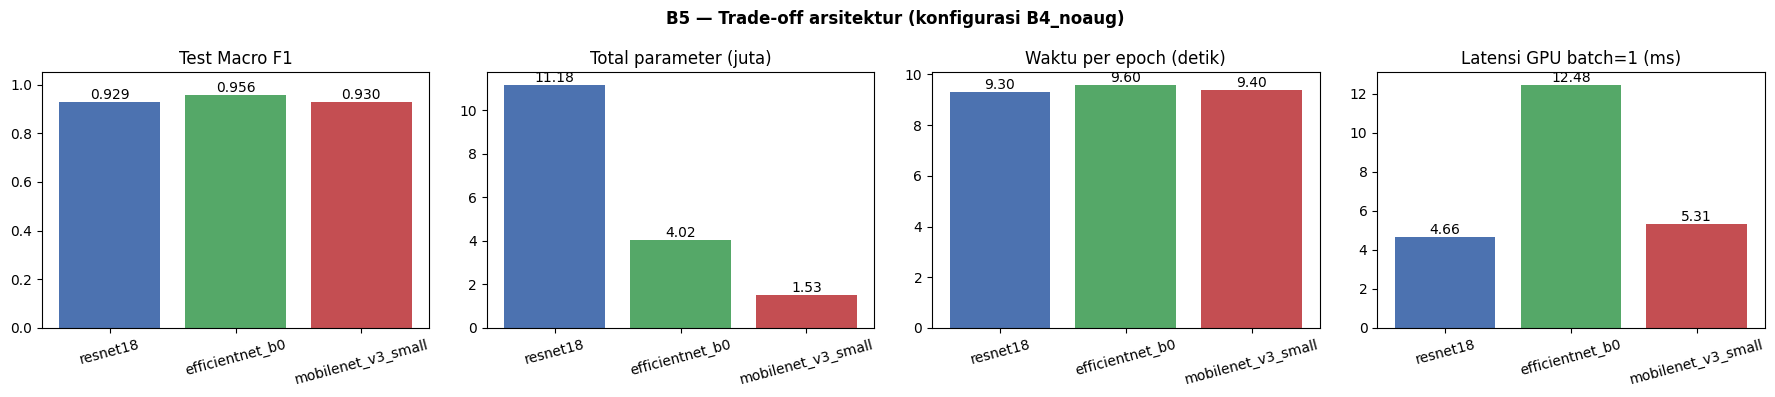

In [49]:
#Perbandingan trade-off: performa vs parameter vs komputasi
@torch.no_grad()
def measure_latency(model, batch_size=1, n_warmup=10, n_iter=50):
    """Latensi forward murni di GPU (tanpa data loading) pada input 224x224."""
    model.eval()
    x = torch.randn(batch_size, 3, 224, 224, device=DEVICE)
    for _ in range(n_warmup):
        model(x)
    sync(); t0 = time.perf_counter()
    for _ in range(n_iter):
        model(x)
    sync()
    return 1000 * (time.perf_counter() - t0) / n_iter

compare_ids = [BEST_EXP] + [e for e in ["B5_effnet_b0", "B5_mnv3_small"] if e in RESULTS]
for e in compare_ids:
    r = RESULTS[e]
    r["gflops_224"] = ARCH_WEIGHTS[r["arch"]].meta.get("_ops")   # GFLOPs per citra (dari metadata torchvision)
    r["latency_ms_bs1"] = round(measure_latency(MODELS[e], 1), 2)
    r["latency_ms_bs32"] = round(measure_latency(MODELS[e], 32), 2)
save_logs()   # angka latensi ikut tersimpan di log mentah

cmp_cols = ["experiment", "arch", "strategy", "total_params", "trainable_params", "gflops_224",
            "best_epoch", "train_time_s", "sec_per_epoch", "peak_gpu_mem_mb",
            "latency_ms_bs1", "latency_ms_bs32", "val_acc", "test_macro_f1"]
cmp_df = pd.DataFrame([RESULTS[e] for e in compare_ids])[cmp_cols]
display(cmp_df)

# Grafik trade-off
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
labels = cmp_df["arch"].tolist()
colors = ["#4C72B0", "#55A868", "#C44E52"][:len(labels)]
panels = [("test_macro_f1", "Test Macro F1", 1.0),
          ("total_params", "Total parameter (juta)", 1e6),
          ("sec_per_epoch", "Waktu per epoch (detik)", 1.0),
          ("latency_ms_bs1", "Latensi GPU batch=1 (ms)", 1.0)]
for ax, (col, title, scale) in zip(axes, panels):
    vals = cmp_df[col] / scale
    bars = ax.bar(labels, vals, color=colors)
    ax.bar_label(bars, fmt="%.3f" if col == "test_macro_f1" else "%.2f")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylim(0, 1.05)
plt.suptitle(f"B5 — Trade-off arsitektur (konfigurasi {BEST_EXP})", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "b5_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()


#Visualisasi Untuk Report

In [50]:
summary = pd.read_csv(OUT_DIR / "summary_metrics.csv")

ORDER = ["B1", "B2", "B3", "B4_noaug", "B5_effnet_b0", "B5_mnv3_small"]
KODE = {"B1": "B1", "B2": "B2", "B3": "B3 / B4 (dengan aug)", "B4_noaug": "B4 (tanpa aug)",
        "B5_effnet_b0": "B5a", "B5_mnv3_small": "B5b"}
STRATEGI = {"from_scratch": "From scratch", "feature_extraction": "Feature extraction",
            "finetune_layer4": "Fine-tuning (layer4 + fc)", "finetune": "Fine-tuning (stage akhir + head)"}
ARSITEKTUR = {"resnet18": "ResNet-18", "efficientnet_b0": "EfficientNet-B0",
              "mobilenet_v3_small": "MobileNetV3-Small"}

summary = summary[summary["experiment"].isin(ORDER)].copy()
summary["_order"] = summary["experiment"].map(ORDER.index)
summary = summary.sort_values("_order").reset_index(drop=True)

c1_table = pd.DataFrame({
    "Kode":             summary["experiment"].map(KODE),
    "Arsitektur":       summary["arch"].map(ARSITEKTUR),
    "Strategi":         summary["strategy"].map(STRATEGI),
    "Augmentasi":       summary["augmentation"].map({True: "Ya", False: "Tidak"}),
    "Trainable params": summary["trainable_params"].map("{:,}".format),
    "Total params":     summary["total_params"].map("{:,}".format),
    "% trainable":      summary["trainable_pct"].map("{:.2f}%".format),
    "Learning rate":    summary["lr_groups"],
    "Epoch konvergen":  summary["best_epoch"].astype(str) + " / " + summary["epochs_run"].astype(str),
    "Waktu latih (s)":  summary["train_time_s"].map("{:.1f}".format),
    "Val acc":          (100 * summary["val_acc"]).map("{:.2f}%".format),
    "Test Macro F1":    summary["test_macro_f1"].map("{:.4f}".format),
})

display(c1_table.style.hide(axis="index"))
print("Epoch konvergen = epoch dengan validation loss terendah / total epoch hingga early stopping.")

# Simpan untuk laporan
c1_table.to_csv(OUT_DIR / "c1_consolidated_table.csv", index=False)
try:
    md = c1_table.to_markdown(index=False)
    (OUT_DIR / "c1_consolidated_table.md").write_text(md)
    print("\nVersi Markdown (siap salin ke laporan):\n")
    print(md)
except ImportError:
    print("Paket 'tabulate' tidak ada; jalankan !pip install tabulate untuk versi Markdown.")

Kode,Arsitektur,Strategi,Augmentasi,Trainable params,Total params,% trainable,Learning rate,Epoch konvergen,Waktu latih (s),Val acc,Test Macro F1
B1,ResNet-18,From scratch,Ya,"11,181,642","11,181,642",100.00%,all=0.001,11 / 16,238.5,46.64%,0.4755
B2,ResNet-18,Feature extraction,Ya,"5,130","11,181,642",0.05%,fc=0.001,12 / 17,233.8,89.26%,0.9026
B3 / B4 (dengan aug),ResNet-18,Fine-tuning (layer4 + fc),Ya,"8,398,858","11,181,642",75.11%,layer4=0.0001; fc=0.001,4 / 9,124.1,90.94%,0.9295
B4 (tanpa aug),ResNet-18,Fine-tuning (layer4 + fc),Tidak,"8,398,858","11,181,642",75.11%,layer4=0.0001; fc=0.001,4 / 9,83.8,92.62%,0.9286
B5a,EfficientNet-B0,Fine-tuning (stage akhir + head),Tidak,"3,168,550","4,020,358",78.81%,features[6:]=0.0001; classifier[1]=0.001,4 / 9,86.5,92.95%,0.9562
B5b,MobileNetV3-Small,Fine-tuning (stage akhir + head),Tidak,"1,337,586","1,528,106",87.53%,features[9:]+classifier[0]=0.0001; classifier[3]=0.001,4 / 9,84.9,89.60%,0.9296


Epoch konvergen = epoch dengan validation loss terendah / total epoch hingga early stopping.

Versi Markdown (siap salin ke laporan):

| Kode                 | Arsitektur        | Strategi                         | Augmentasi   | Trainable params   | Total params   | % trainable   | Learning rate                                          | Epoch konvergen   |   Waktu latih (s) | Val acc   |   Test Macro F1 |
|:---------------------|:------------------|:---------------------------------|:-------------|:-------------------|:---------------|:--------------|:-------------------------------------------------------|:------------------|------------------:|:----------|----------------:|
| B1                   | ResNet-18         | From scratch                     | Ya           | 11,181,642         | 11,181,642     | 100.00%       | all=0.001                                              | 11 / 16           |             238.5 | 46.64%    |          0.4755 |
| B2                   | ResNet-18   

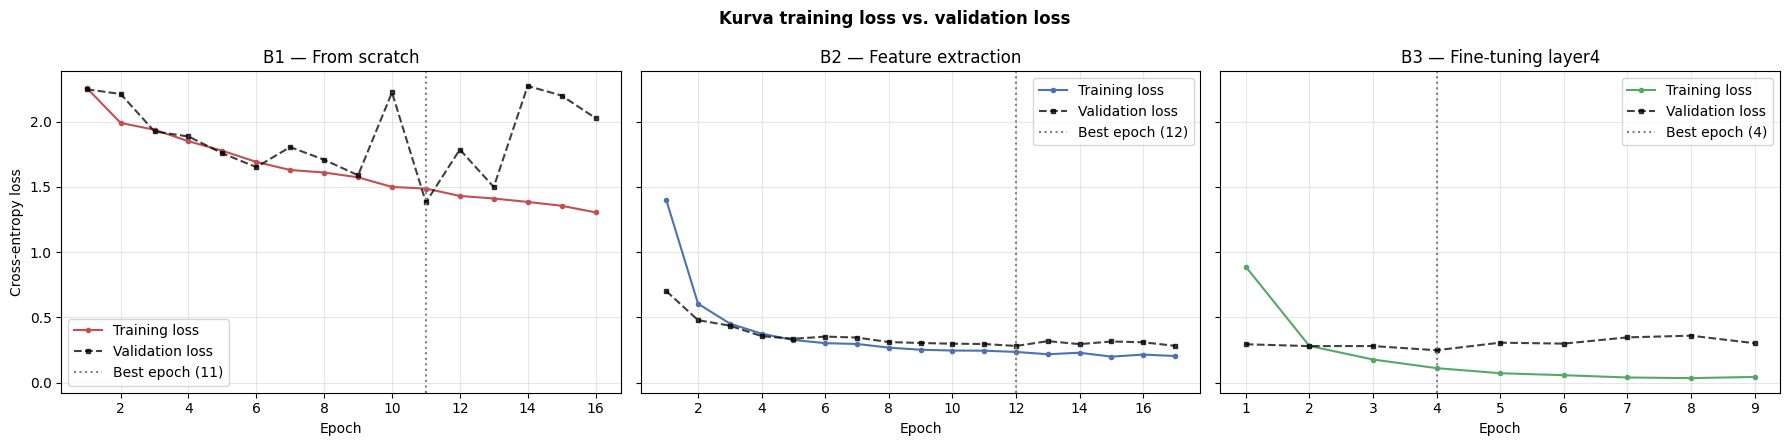

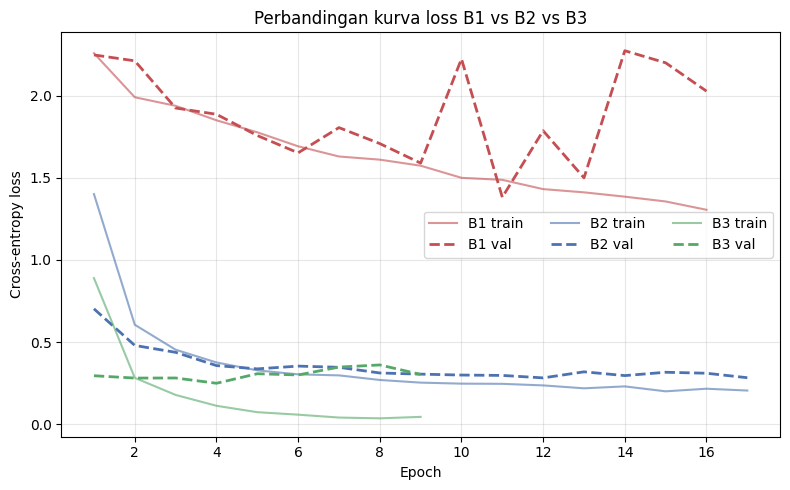

In [51]:
logs = pd.read_csv(OUT_DIR / "epoch_logs.csv")
CURVE_EXPS = [("B1", "B1 — From scratch"),
              ("B2", "B2 — Feature extraction"),
              ("B3", "B3 — Fine-tuning layer4")]
CURVE_EXPS = [(e, t) for e, t in CURVE_EXPS if e in set(logs["experiment"])]
COLORS = {"B1": "#C44E52", "B2": "#4C72B0", "B3": "#55A868"}

# (a) Per kondisi, sumbu-y disamakan agar skala loss dapat dibandingkan langsung
fig, axes = plt.subplots(1, len(CURVE_EXPS), figsize=(6 * len(CURVE_EXPS), 4.5), sharey=True)
for ax, (e, title) in zip(np.atleast_1d(axes), CURVE_EXPS):
    h = logs[logs["experiment"] == e]
    best = int(summary.loc[summary["experiment"] == e, "best_epoch"].iloc[0])
    ax.plot(h["epoch"], h["train_loss"], "o-", ms=3, color=COLORS[e], label="Training loss")
    ax.plot(h["epoch"], h["val_loss"], "s--", ms=3, color="black", alpha=0.75, label="Validation loss")
    ax.axvline(best, ls=":", color="gray", label=f"Best epoch ({best})")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
np.atleast_1d(axes)[0].set_ylabel("Cross-entropy loss")
plt.suptitle("Kurva training loss vs. validation loss", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "c1_loss_curves_B1_B2_B3.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) Overlay ketiga kondisi dalam satu grafik
fig, ax = plt.subplots(figsize=(8, 5))
for e, title in CURVE_EXPS:
    h = logs[logs["experiment"] == e]
    ax.plot(h["epoch"], h["train_loss"], "-", color=COLORS[e], alpha=0.6, label=f"{e} train")
    ax.plot(h["epoch"], h["val_loss"], "--", color=COLORS[e], lw=2, label=f"{e} val")
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Perbandingan kurva loss B1 vs B2 vs B3")
ax.grid(alpha=0.3)
ax.legend(ncol=3)
plt.tight_layout()
plt.savefig(FIG_DIR / "c1_loss_overlay_B1_B2_B3.png", dpi=150, bbox_inches="tight")
plt.show()

In [53]:
!zip -r outputs.zip outputs/


  adding: outputs/ (stored 0%)
  adding: outputs/summary_metrics.csv (deflated 51%)
  adding: outputs/epoch_logs.csv (deflated 61%)
  adding: outputs/figures/ (stored 0%)
  adding: outputs/figures/c1_loss_curves_B1_B2_B3.png (deflated 10%)
  adding: outputs/figures/c1_loss_overlay_B1_B2_B3.png (deflated 7%)
  adding: outputs/figures/b5_tradeoff.png (deflated 18%)
  adding: outputs/test_predictions.csv (deflated 86%)
  adding: outputs/checkpoints/ (stored 0%)
  adding: outputs/checkpoints/B1.pt (deflated 7%)
  adding: outputs/checkpoints/B5_mnv3_small.pt (deflated 8%)
  adding: outputs/checkpoints/B4_noaug.pt (deflated 7%)
  adding: outputs/checkpoints/B5_effnet_b0.pt (deflated 8%)
  adding: outputs/checkpoints/B2.pt (deflated 7%)
  adding: outputs/checkpoints/B3.pt (deflated 7%)
  adding: outputs/data_split.csv (deflated 94%)
  adding: outputs/c1_consolidated_table.csv (deflated 49%)
  adding: outputs/c1_consolidated_table.md (deflated 72%)
  adding: outputs/metrics_log.json (deflated 

#untuk Failure Analysis


In [60]:
import textwrap

summary = pd.read_csv(OUT_DIR / "summary_metrics.csv")
predictions = pd.read_csv(OUT_DIR / "test_predictions.csv")

best_row = summary.loc[summary["val_acc"].idxmax()]
BEST_EXP = best_row["experiment"]

best_errors = predictions[
    (predictions["experiment"] == BEST_EXP) &
    (predictions["correct"] == False)
].copy()

best_errors = best_errors.sort_values("confidence", ascending=False)

print("Model terbaik :", BEST_EXP)
print("Validation acc:", f"{best_row['val_acc']:.2%}")
print("Test Macro F1 :", f"{best_row['test_macro_f1']:.4f}")
print("Jumlah salah  :", len(best_errors))

assert len(best_errors) > 0, "Tidak ditemukan sampel yang salah diprediksi."

# Ambil satu kesalahan paling yakin dari setiap ground-truth agar sampel beragam
diverse_errors = (
    best_errors.groupby("true_label", group_keys=False)
    .head(1)
    .sort_values("confidence", ascending=False)
)

# Isi hingga maksimal 6 sampel jika kelas yang salah kurang dari 6
selected_indices = list(diverse_errors.index[:6])

if len(selected_indices) < 6:
    remaining = best_errors.loc[
        ~best_errors.index.isin(selected_indices)
    ].index.tolist()

    selected_indices.extend(remaining[:6 - len(selected_indices)])

error_samples = best_errors.loc[selected_indices].head(6).reset_index(drop=True)

display(error_samples[
    ["path", "true_label", "pred_label", "confidence"]
])

Model terbaik : B5_effnet_b0
Validation acc: 92.95%
Test Macro F1 : 0.9562
Jumlah salah  : 13


,path,true_label,pred_label,confidence
0,/content/data/oxford-iiit-pet/images/Birman_36...,Birman,Ragdoll,0.896247
1,/content/data/oxford-iiit-pet/images/staffords...,Staffordshire Bull Terrier,American Pit Bull Terrier,0.829777
2,/content/data/oxford-iiit-pet/images/american_...,American Pit Bull Terrier,Staffordshire Bull Terrier,0.790265
3,/content/data/oxford-iiit-pet/images/Ragdoll_1...,Ragdoll,Birman,0.643217
4,/content/data/oxford-iiit-pet/images/beagle_14...,Beagle,Basset Hound,0.607707
5,/content/data/oxford-iiit-pet/images/Bengal_13...,Bengal,Siamese,0.379703


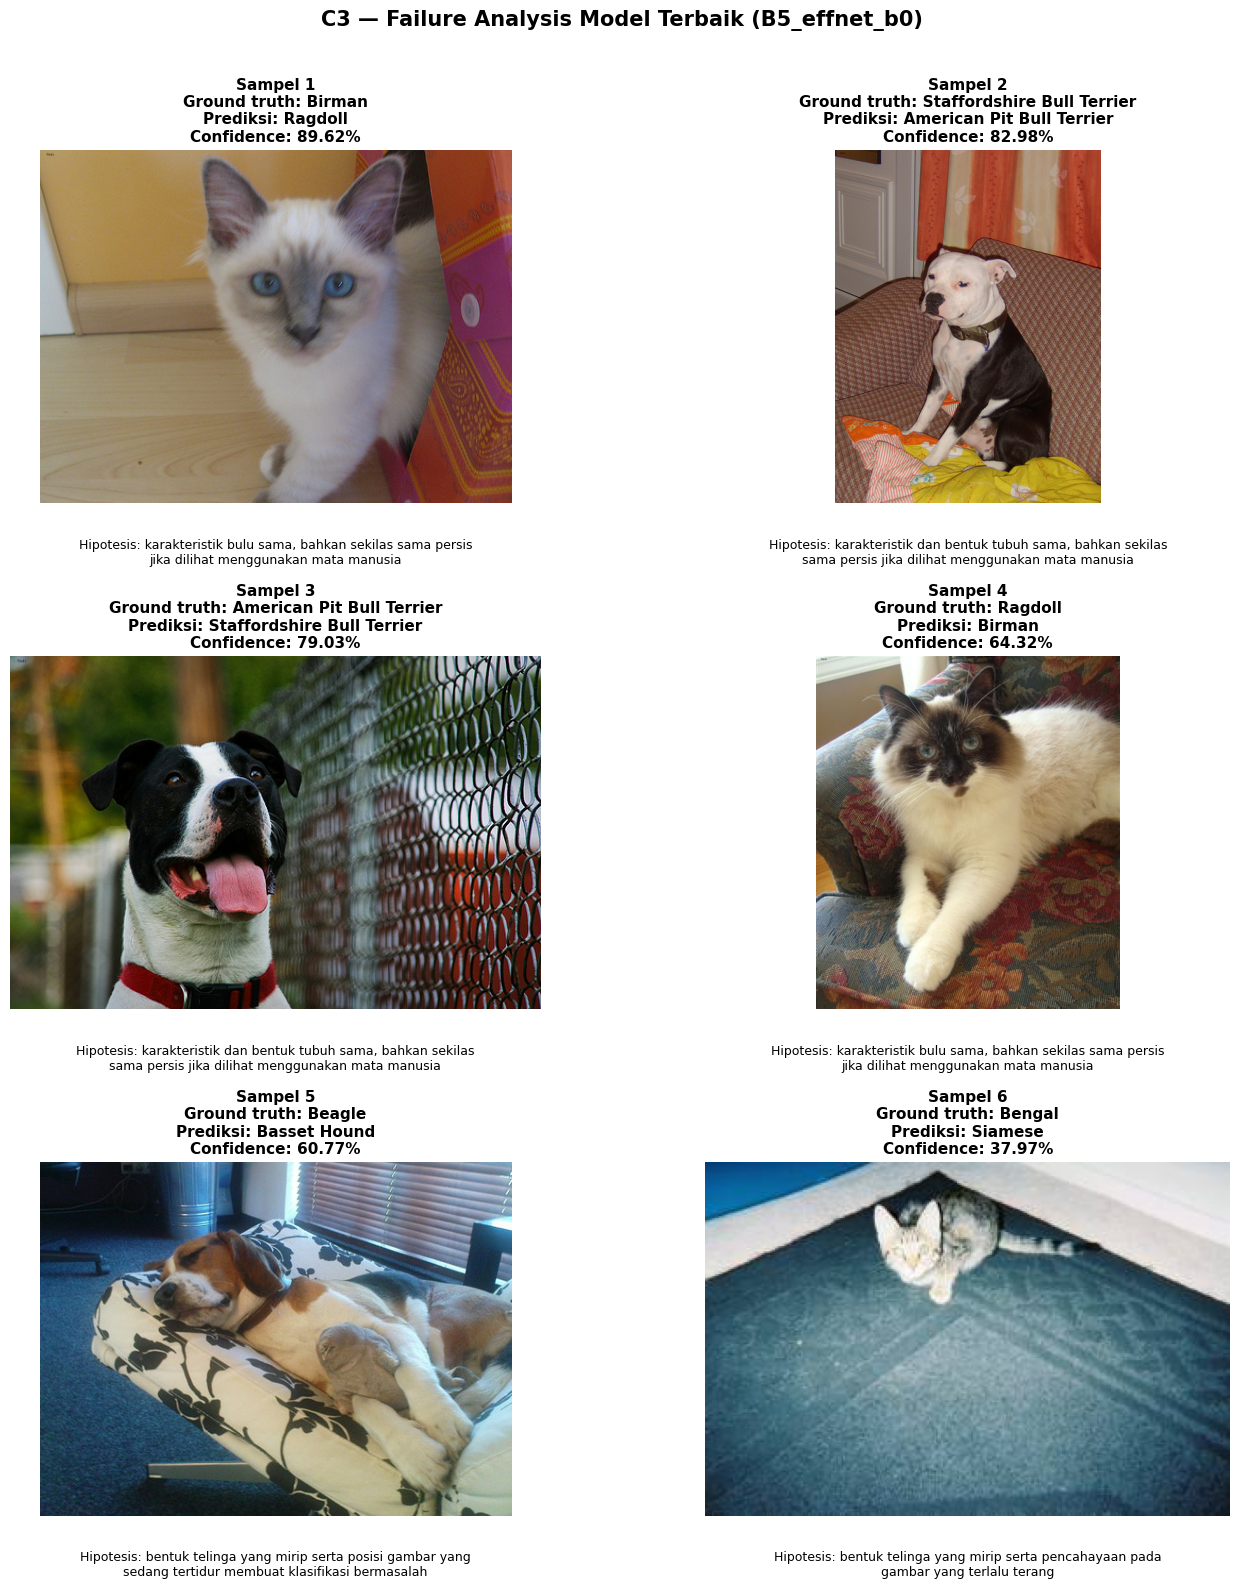

,sample,path,true_label,pred_label,confidence,hypothesis
0,1,/content/data/oxford-iiit-pet/images/Birman_36...,Birman,Ragdoll,0.8962,"karakteristik bulu sama, bahkan sekilas sama p..."
1,2,/content/data/oxford-iiit-pet/images/staffords...,Staffordshire Bull Terrier,American Pit Bull Terrier,0.8298,"karakteristik dan bentuk tubuh sama, bahkan se..."
2,3,/content/data/oxford-iiit-pet/images/american_...,American Pit Bull Terrier,Staffordshire Bull Terrier,0.7903,"karakteristik dan bentuk tubuh sama, bahkan se..."
3,4,/content/data/oxford-iiit-pet/images/Ragdoll_1...,Ragdoll,Birman,0.6432,"karakteristik bulu sama, bahkan sekilas sama p..."
4,5,/content/data/oxford-iiit-pet/images/beagle_14...,Beagle,Basset Hound,0.6077,bentuk telinga yang mirip serta posisi gambar ...
5,6,/content/data/oxford-iiit-pet/images/Bengal_13...,Bengal,Siamese,0.3797,bentuk telinga yang mirip serta pencahayaan pa...


Gambar disimpan di: /content/outputs/figures/c3_failure_analysis.png
Tabel disimpan di : /content/outputs/c3_failure_analysis.csv
Seluruh hipotesis telah diisi.


In [61]:
MANUAL_HYPOTHESES = {
    1: "karakteristik bulu sama, bahkan sekilas sama persis jika dilihat menggunakan mata manusia",
    2: "karakteristik dan bentuk tubuh sama, bahkan sekilas sama persis jika dilihat menggunakan mata manusia",
    3: "karakteristik dan bentuk tubuh sama, bahkan sekilas sama persis jika dilihat menggunakan mata manusia",
    4: "karakteristik bulu sama, bahkan sekilas sama persis jika dilihat menggunakan mata manusia",
    5: "bentuk telinga yang mirip serta posisi gambar yang sedang tertidur membuat klasifikasi bermasalah",
    6: "bentuk telinga yang mirip serta pencahayaan pada gambar yang terlalu terang"
}

# Masukkan hipotesis manual ke DataFrame
error_samples = error_samples.copy()
error_samples["hypothesis"] = [
    MANUAL_HYPOTHESES.get(i + 1, "").strip()
    for i in range(len(error_samples))
]

# Beri peringatan jika masih ada hipotesis kosong
empty_samples = [
    i + 1
    for i, hypothesis in enumerate(error_samples["hypothesis"])
    if not hypothesis
]

if empty_samples:
    print(
        "PERINGATAN: Hipotesis sampel berikut belum diisi:",
        empty_samples
    )
    print("Amati gambar, isi MANUAL_HYPOTHESES, lalu jalankan ulang sel ini.\n")

# Buat visualisasi
n = len(error_samples)
ncols = 2
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 5.5 * nrows)
)
axes = np.array(axes).reshape(-1)

for i, (ax, row) in enumerate(
    zip(axes, error_samples.to_dict("records"))
):
    try:
        image = Image.open(row["path"]).convert("RGB")
        ax.imshow(image)
        ax.axis("off")

        ax.set_title(
            f"Sampel {i + 1}\n"
            f"Ground truth: {row['true_label']}\n"
            f"Prediksi: {row['pred_label']}\n"
            f"Confidence: {row['confidence']:.2%}",
            fontsize=11,
            fontweight="bold"
        )

        hypothesis = (
            row["hypothesis"]
            if row["hypothesis"]
            else "[Hipotesis belum diisi]"
        )

        ax.text(
            0.5,
            -0.10,
            textwrap.fill(
                "Hipotesis: " + hypothesis,
                width=65
            ),
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9,
            color="black" if row["hypothesis"] else "red"
        )

    except (FileNotFoundError, OSError) as error:
        ax.axis("off")
        ax.set_title(
            f"Sampel {i + 1} gagal ditampilkan\n{error}",
            color="red"
        )

# Sembunyikan subplot yang tidak terpakai
for ax in axes[n:]:
    ax.axis("off")

plt.suptitle(
    f"C3 — Failure Analysis Model Terbaik ({BEST_EXP})",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout(rect=[0, 0.02, 1, 0.97])

figure_path = FIG_DIR / "c3_failure_analysis.png"
plt.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Simpan tabel pendukung
failure_table = error_samples[
    ["path", "true_label", "pred_label", "confidence", "hypothesis"]
].copy()

failure_table.insert(
    0,
    "sample",
    range(1, len(failure_table) + 1)
)
failure_table["confidence"] = failure_table["confidence"].round(4)

table_path = OUT_DIR / "c3_failure_analysis.csv"
failure_table.to_csv(table_path, index=False)

display(failure_table)

print("Gambar disimpan di:", figure_path)
print("Tabel disimpan di :", table_path)

if not empty_samples:
    print("Seluruh hipotesis telah diisi.")
